# **MÓDULO 13**
# Projeto - Fundamentos da Descoberta de Dados

Nesse projeto trabalharemos com a base de dados de produtos de um supermercado do Chile.
A ideia é que vocês apliquem os conceitos estatísticos vistos no último módulo, mais os conceitos de visualizações de dados através de gráficos e finalizem publicando no seu github!

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

os.makedirs("imagens", exist_ok=True)   # pasta onde os gráficos serão salvos
AZUL = "#257de0"                         # cor única dos gráficos (uma série = um tom)

Faça a leitura dos dados do arquivo CSV:


Altere o código abaixo de acordo com seu diretório.

In [2]:
# O CSV enviado usa vírgula como separador (e não ponto e vírgula)
df = pd.read_csv("MODULO7_PROJETOFINAL_BASE_SUPERMERCADO.csv", sep=",")

print(df.shape)
df.head(10)

(1107, 7)


,title,Marca,Preco_Normal,Preco_Desconto,Preco_Anterior,Desconto,Categoria
0,"Pack 12 un, Leche extra proteína 1 L",Loncoleche,19788,0,0,0,lacteos
1,"Pack 12 un, Leche chocolate receta original 1 L",Soprole,18228,0,0,0,lacteos
2,"Pack 12 un, Leche semidescremada chocolate 1 L",Soprole,18228,0,0,0,lacteos
3,"Pack 12 un, Leche semidescremada frutilla 1 L",Soprole,18228,0,0,0,lacteos
4,"Pack 12 un, Leche sin lactosa chocolate 1 L",Loncoleche,17988,0,0,0,lacteos
5,"Pack 12 un, Leche sin lactosa frutilla 1 L",Loncoleche,17988,0,0,0,lacteos
6,"Pack 12 un, Leche saborizada light chocolate 1 L",Loncoleche,17988,0,0,0,lacteos
7,"Pack 12 un, Leche saborizada frutilla 1 L",Colun,17388,0,0,0,lacteos
8,"Pack 12 un, Leche saborizada vainilla 1 L",Colun,17388,0,0,0,lacteos
9,"Pack 12 un, Leche saborizada manjar 1 L",Colun,17388,0,0,0,lacteos


**Checagem rápida da base** – antes de calcular qualquer estatística, vale entender o que há nela.

In [3]:
print(df.isna().sum().sum(), "valores nulos")
print((df["Preco_Normal"] == 0).sum(), "produtos com Preco_Normal = 0")
print((df["Desconto"] > 0).sum(), "produtos com desconto aplicado")
print()
print(df["Categoria"].value_counts())

0 valores nulos
294 produtos com Preco_Normal = 0
118 produtos com desconto aplicado

Categoria
lacteos                       447
belleza-y-cuidado-personal    239
congelados                    235
verduras                       64
instantaneos-y-sopas           57
comidas-preparadas             46
frutas                         19
Name: count, dtype: int64


> **Atenção – Preco_Normal = 0:** 294 dos 1.107 produtos têm `Preco_Normal` igual a 0. São produtos que aparecem na base só com `Preco_Desconto` preenchido (ou sem nenhum preço). Seguindo o enunciado, as análises 1 a 3 usam a coluna `Preco_Normal` **como ela vem na base**; logo depois de cada resultado mostro como a conclusão muda se esses zeros forem removidos.

Os campos do nosso dataframe são:

**Title:** Nome do produto.


**Marca:** A marca do produto.


**Preco_Normal:** O preço em que o produto costuma ser vendido quando não há desconto.


**Preco_Desconto:** O preço vendido após o desconto ser aplicado.


**Preco_Anterior:** Preço em que era comercializado o produto antes do desconto aplicado.


**Desconto:** Total de desconto aplicado.






As colunas que aparecem com valores 0 são para os produtos onde não tivemos descontos aplicados.


As categorias estão em espanhol!

# 1 - Traga a média e a mediana dos preços - coluna Preco_Normal - por categoria de produto.
# Identifique as categorias que parecem ter um valor de média abaixo ou acima da mediana.

In [4]:
# Média de Preco_Normal por categoria
media = df.groupby("Categoria")["Preco_Normal"].mean().round(1)
media

Categoria
belleza-y-cuidado-personal    1783.6
comidas-preparadas            3095.0
congelados                    2108.0
frutas                        1724.5
instantaneos-y-sopas           765.5
lacteos                       2385.2
verduras                      1343.3
Name: Preco_Normal, dtype: float64

In [5]:
# Mediana de Preco_Normal por categoria
mediana = df.groupby("Categoria")["Preco_Normal"].median()
mediana

Categoria
belleza-y-cuidado-personal    1569.0
comidas-preparadas            3290.0
congelados                    1519.0
frutas                        1195.0
instantaneos-y-sopas           439.0
lacteos                        989.0
verduras                      1180.0
Name: Preco_Normal, dtype: float64

In [6]:
# Comparando média x mediana lado a lado
comp = pd.DataFrame({"media": media, "mediana": mediana})
comp["media - mediana"] = (comp["media"] - comp["mediana"]).round(1)
comp["media / mediana"] = (comp["media"] / comp["mediana"]).round(2)
comp["posicao da media"] = np.where(comp["media"] > comp["mediana"], "ACIMA da mediana", "ABAIXO da mediana")
comp.sort_values("media / mediana", ascending=False)

,media,mediana,media - mediana,media / mediana,posicao da media
Categoria,,,,,
lacteos,2385.2,989.0,1396.2,2.41,ACIMA da mediana
instantaneos-y-sopas,765.5,439.0,326.5,1.74,ACIMA da mediana
frutas,1724.5,1195.0,529.5,1.44,ACIMA da mediana
congelados,2108.0,1519.0,589.0,1.39,ACIMA da mediana
belleza-y-cuidado-personal,1783.6,1569.0,214.6,1.14,ACIMA da mediana
verduras,1343.3,1180.0,163.3,1.14,ACIMA da mediana
comidas-preparadas,3095.0,3290.0,-195.0,0.94,ABAIXO da mediana


**Categorias com média ACIMA da mediana:** `lacteos` (média 2.385 x mediana 989, ~2,4 vezes), `instantaneos-y-sopas` (~1,7x), `frutas` (~1,4x), `congelados` (~1,4x), e, com diferença bem menor, `belleza-y-cuidado-personal` e `verduras` (~1,1x cada).

**Categoria com média ABAIXO da mediana:** `comidas-preparadas` (média 3.095 x mediana 3.290).

Média maior que a mediana indica uma distribuição assimétrica à direita: poucos produtos muito caros puxam a média para cima (em `lacteos`, por exemplo, os packs de 12 litros e os leites em pó em lata grande).

In [7]:
# Sensibilidade: o que muda se removermos os produtos com Preco_Normal = 0?
com_preco = df[df["Preco_Normal"] > 0]
g = com_preco.groupby("Categoria")["Preco_Normal"]
sens = pd.DataFrame({"media": g.mean().round(1), "mediana": g.median()})
sens["media / mediana"] = (sens["media"] / sens["mediana"]).round(2)
sens.sort_values("media / mediana", ascending=False)

,media,mediana,media / mediana
Categoria,,,
lacteos,3029.0,1719.5,1.76
instantaneos-y-sopas,1179.3,689.0,1.71
frutas,1724.5,1195.0,1.44
belleza-y-cuidado-personal,2919.7,2179.0,1.34
verduras,1457.1,1250.0,1.17
comidas-preparadas,3954.8,3740.0,1.06
congelados,3020.7,2954.0,1.02


Sem os zeros, **todas** as categorias ficam com média acima da mediana. `comidas-preparadas` passa para o lado de cima (3.955 x 3.740) porque 10 dos seus 46 produtos tinham preço 0, o que puxava a média para baixo. Ou seja: a posição "abaixo da mediana" dessa categoria vem dos zeros da base, não de produtos baratos. As demais conclusões se mantêm.

# 2 - Traga o desvio padrão por categoria de produto.
# Qual o comportamento da média e mediana nas categorias com maior desvio?

In [8]:
# Desvio padrão de Preco_Normal por categoria
desvio = df.groupby("Categoria")["Preco_Normal"].std().round(1)

resumo = comp[["media", "mediana"]].copy()
resumo["desvio padrao"] = desvio
resumo["media - mediana"] = comp["media - mediana"]
resumo.sort_values("desvio padrao", ascending=False)

,media,mediana,desvio padrao,media - mediana
Categoria,,,,
lacteos,2385.2,989.0,3925.8,1396.2
belleza-y-cuidado-personal,1783.6,1569.0,2210.0,214.6
congelados,2108.0,1519.0,2111.5,589.0
comidas-preparadas,3095.0,3290.0,2019.9,-195.0
frutas,1724.5,1195.0,1639.2,529.5
instantaneos-y-sopas,765.5,439.0,1170.2,326.5
verduras,1343.3,1180.0,1012.7,163.3


**Comportamento observado:** a categoria com maior desvio padrão é `lacteos` (≈ 3.926), seguida de `belleza-y-cuidado-personal` (≈ 2.210) e `congelados` (≈ 2.112).

Nessas três, a média fica **acima** da mediana, e `lacteos` é o caso mais forte: média 2.385 contra mediana 989. Quanto maior a dispersão, mais a média é arrastada pelos valores extremos e menos ela representa o preço "típico"; nesses casos a mediana é a medida mais confiável.

A exceção é `comidas-preparadas` (4º maior desvio, ≈ 2.020), que tem média abaixo da mediana pelo efeito dos preços 0 descrito acima. Sem os zeros, `lacteos` continua sendo a categoria de maior desvio (≈ 4.199).

# 3 - Plot um boxplot da distribuição do Preco_Normal para a categoria que você identificou que tem o maior desvio padrão. Como é a distribuição desses dados segundo o boxplot? Você identifica muitos outliers?

Dica: Para trazer apenas os dados da categoria que você deseja você pode usar o df.loc[df['Categoria'] == 'CATEGORIA ESCOLHIDA'

Categoria com maior desvio padrão: lacteos


/tmp/ipykernel_504/2905463009.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(


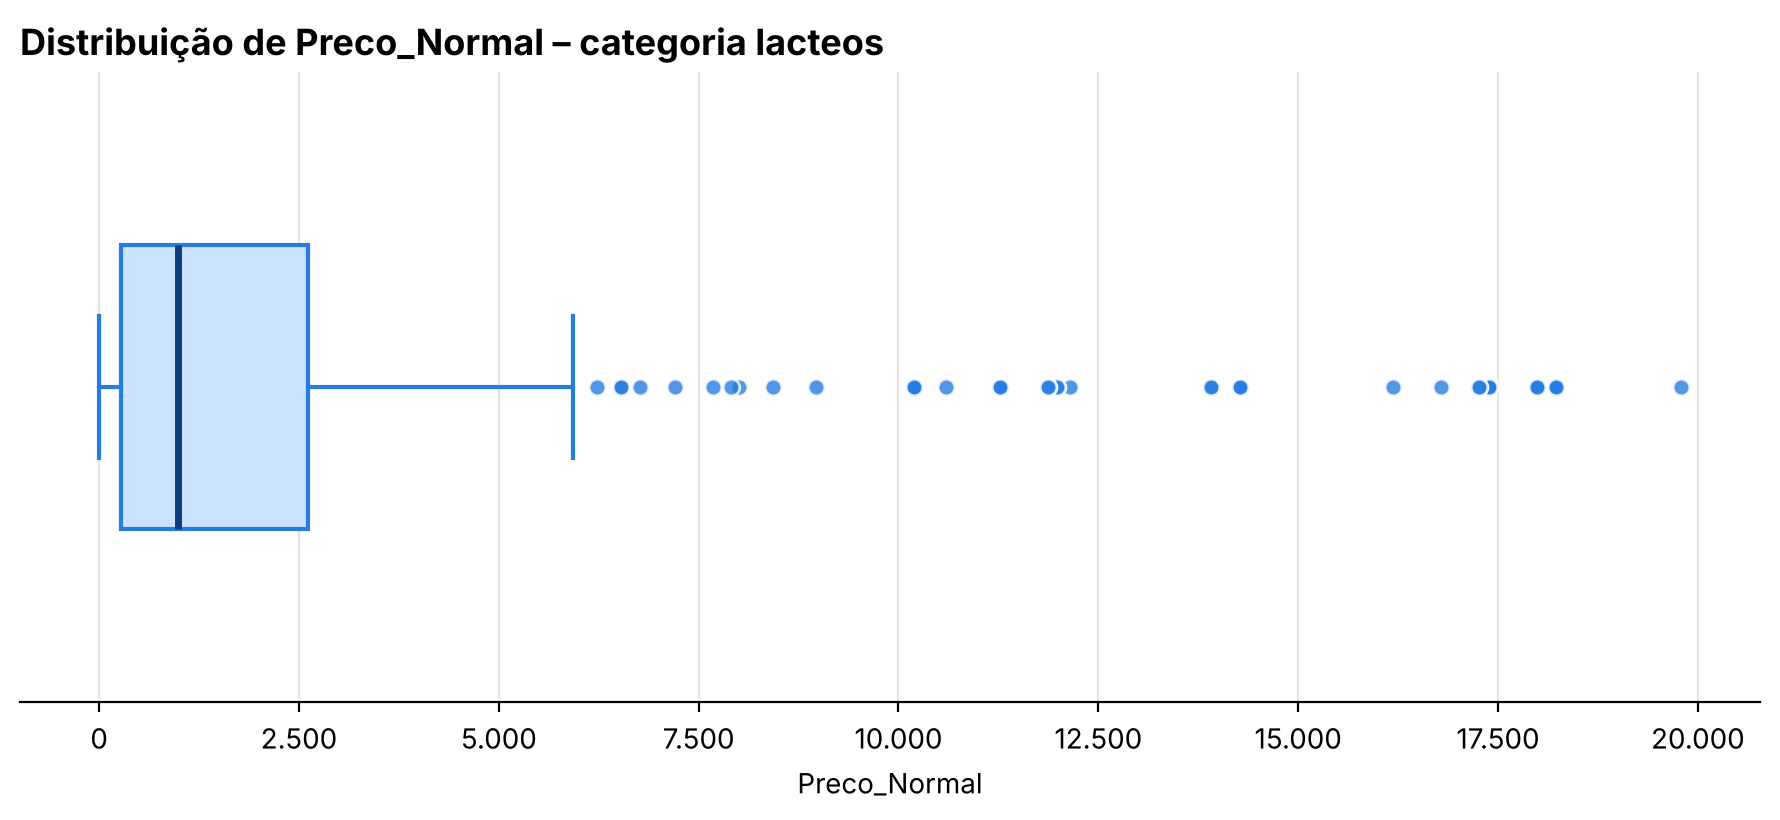

In [9]:
categoria_max = desvio.idxmax()
print("Categoria com maior desvio padrão:", categoria_max)

lacteos = df.loc[df["Categoria"] == categoria_max, "Preco_Normal"]

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.boxplot(
    lacteos, vert=False, widths=0.45, patch_artist=True,
    boxprops=dict(facecolor="#cce3fd", edgecolor=AZUL, linewidth=1.5),
    medianprops=dict(color="#0e3d7e", linewidth=2.5),
    whiskerprops=dict(color=AZUL, linewidth=1.5),
    capprops=dict(color=AZUL, linewidth=1.5),
    flierprops=dict(marker="o", markerfacecolor=AZUL, markeredgecolor="white", markersize=6, alpha=0.8),
)
ax.set_title("Distribuição de Preco_Normal – categoria lacteos", loc="left", fontsize=13, fontweight="bold")
ax.set_xlabel("Preco_Normal")
ax.set_yticks([])
ax.xaxis.set_major_formatter(lambda v, _: f"{v:,.0f}".replace(",", "."))
ax.grid(axis="x", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
for lado in ["top", "right", "left"]:
    ax.spines[lado].set_visible(False)
plt.tight_layout()
plt.savefig("imagens/boxplot_lacteos.png", dpi=200, facecolor="white")
plt.show()

In [10]:
# Números por trás do boxplot (método IQR, o mesmo que o matplotlib usa para os bigodes)
q1, med, q3 = lacteos.quantile([0.25, 0.5, 0.75])
iqr = q3 - q1
limite_sup = q3 + 1.5 * iqr
limite_inf = q1 - 1.5 * iqr

print(f"Q1 = {q1:.0f} | Mediana = {med:.0f} | Q3 = {q3:.0f} | IQR = {iqr:.0f}")
print(f"Limite inferior = {limite_inf:.0f} | Limite superior = {limite_sup:.0f}")
print(f"Máximo = {lacteos.max()}")

Q1 = 269 | Mediana = 989 | Q3 = 2609 | IQR = 2340
Limite inferior = -3241 | Limite superior = 6119
Máximo = 19788


**Como é a distribuição?** Fortemente assimétrica à direita. A caixa (Q1 = 269 a Q3 = 2.609) fica comprimida à esquerda, com a mediana em 989 bem perto do início, e o bigode superior se estende até o limite de 6.119. Depois dele há uma sequência de pontos isolados que vai até 19.788.

**Tem muitos outliers?** Sim, e todos do lado de cima. O limite inferior é negativo (−3.241), então não há outliers abaixo.

# Identificação dos outliers do boxplot

In [11]:
outliers = (
    df.loc[(df["Categoria"] == categoria_max) & (df["Preco_Normal"] > limite_sup),
           ["title", "Marca", "Preco_Normal"]]
    .sort_values("Preco_Normal", ascending=False)
)
print(len(outliers), "outliers em", len(lacteos), "produtos de lacteos",
      f"({len(outliers) / len(lacteos):.1%})")
outliers

43 outliers em 447 produtos de lacteos (9.6%)


,title,Marca,Preco_Normal
0,"Pack 12 un, Leche extra proteína 1 L",Loncoleche,19788
1,"Pack 12 un, Leche chocolate receta original 1 L",Soprole,18228
2,"Pack 12 un, Leche semidescremada chocolate 1 L",Soprole,18228
3,"Pack 12 un, Leche semidescremada frutilla 1 L",Soprole,18228
4,"Pack 12 un, Leche sin lactosa chocolate 1 L",Loncoleche,17988
5,"Pack 12 un, Leche sin lactosa frutilla 1 L",Loncoleche,17988
6,"Pack 12 un, Leche saborizada light chocolate 1 L",Loncoleche,17988
7,"Pack 12 un, Leche saborizada frutilla 1 L",Colun,17388
8,"Pack 12 un, Leche saborizada vainilla 1 L",Colun,17388
9,"Pack 12 un, Leche saborizada manjar 1 L",Colun,17388


In [12]:
n_pack = outliers["title"].str.contains("Pack", case=False).sum()
n_polvo = outliers["title"].str.contains("polvo", case=False).sum()
print(f"Packs (6 ou 12 unidades): {n_pack} | Leite em pó: {n_polvo} | Total: {n_pack + n_polvo}")
print()
print(outliers["Marca"].value_counts().head(5))

Packs (6 ou 12 unidades): 33 | Leite em pó: 10 | Total: 43

Marca
Loncoleche      11
Colun           11
Soprole          6
Cuisine & Co     5
Nido             4
Name: count, dtype: int64


**Quem são os outliers:** são 43 produtos (≈ 9,6% da categoria), todos acima de 6.119. Os 43 se dividem entre **33 packs** de 6 ou 12 unidades de leite (a maioria são os "Pack 12 un" de 1 L, de 10 mil a quase 20 mil) e **10 leites em pó** em embalagem grande (lata de 800 g a 1,6 kg). As marcas que mais aparecem são Loncoleche e Colun (11 cada), seguidas de Soprole (6), Cuisine & Co (5) e Nido (4).

Esses outliers **não parecem erro de digitação**: são produtos legítimos, só que vendidos em formato grande, e por isso custam muito mais que um litro avulso. Para comparar preços de forma justa, o ideal seria olhar o preço por litro/kg, que a base não traz.

# 4 - Plote um gráfico de barras onde temos a média de descontos por categoria.

Categoria
frutas                          0.0
instantaneos-y-sopas            0.0
verduras                        0.0
lacteos                        17.4
comidas-preparadas             43.5
belleza-y-cuidado-personal    123.1
congelados                    154.0
Name: Desconto, dtype: float64


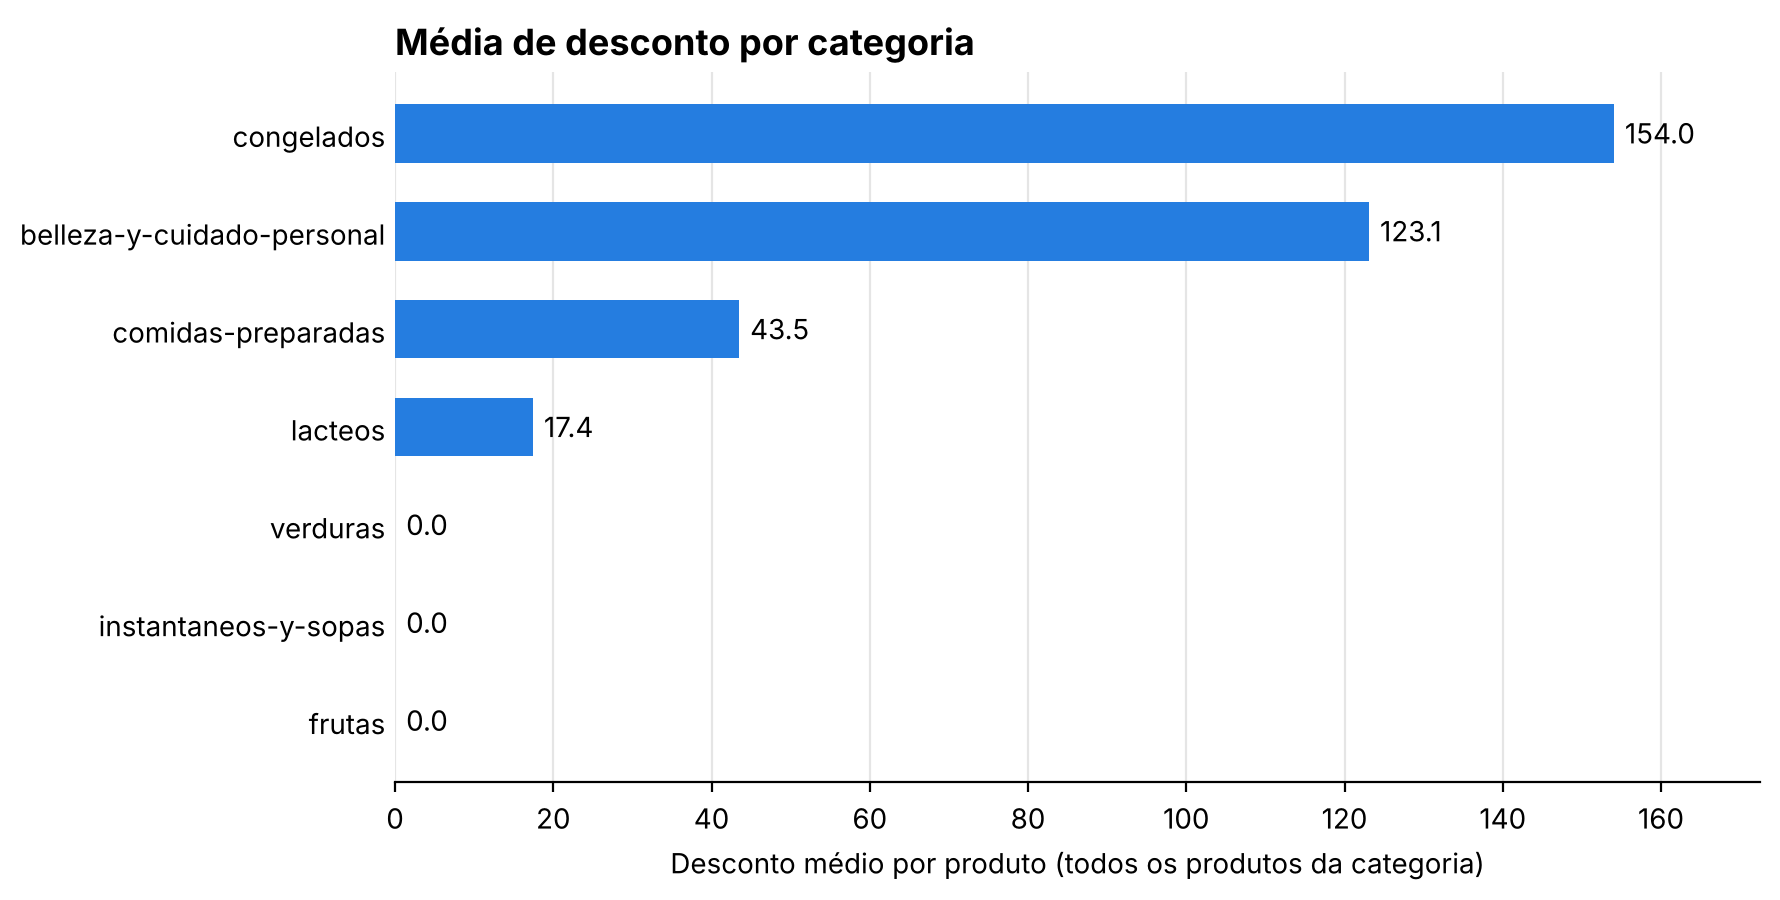

In [13]:
desc_medio = df.groupby("Categoria")["Desconto"].mean().sort_values()
print(desc_medio.round(1))

fig, ax = plt.subplots(figsize=(9, 4.6))
barras = ax.barh(desc_medio.index, desc_medio.values, color=AZUL, height=0.6)
ax.bar_label(barras, labels=[f"{v:,.1f}".replace(",", ".") for v in desc_medio.values], padding=4, fontsize=10)
ax.set_title("Média de desconto por categoria", loc="left", fontsize=13, fontweight="bold")
ax.set_xlabel("Desconto médio por produto (todos os produtos da categoria)")
ax.set_xlim(0, desc_medio.max() * 1.12)
ax.grid(axis="x", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
for lado in ["top", "right", "left"]:
    ax.spines[lado].set_visible(False)
ax.tick_params(axis="y", length=0)
plt.tight_layout()
plt.savefig("imagens/barras_desconto_categoria.png", dpi=200, facecolor="white")
plt.show()

**Leitura:** `congelados` (≈ 154) e `belleza-y-cuidado-personal` (≈ 123) têm os maiores descontos médios, seguidas de `comidas-preparadas` (≈ 43) e `lacteos` (≈ 17). `frutas`, `verduras` e `instantaneos-y-sopas` têm média 0, pois nenhum produto dessas categorias tem desconto na base.

Como a média considera todos os produtos (inclusive os sem desconto), ela mistura "quantos produtos têm desconto" com "quão grande é o desconto". Só 118 dos 1.107 produtos têm desconto; entre os que têm, o desconto médio é de ≈ 684 em `belleza`, ≈ 603 em `congelados` e ≈ 708 em `lacteos` (este com apenas 11 produtos). O valor de `lacteos` na barra é baixo porque poucos dos seus 447 produtos têm desconto.

# 5 - Plote um gráfico de mapa interativo agrupando os dados por categoria, marca e trazendo a média de desconto.

In [14]:
# Mapa interativo (treemap): categoria > marca
#   tamanho do bloco = nº de produtos | cor = média de desconto
mapa = (
    df.groupby(["Categoria", "Marca"])
      .agg(desconto_medio=("Desconto", "mean"), n_produtos=("title", "count"))
      .round(1)
      .reset_index()
)

fig = px.treemap(
    mapa,
    path=[px.Constant("Supermercado"), "Categoria", "Marca"],
    values="n_produtos",
    color="desconto_medio",
    color_continuous_scale=["#cce3fd", "#519ced", "#1b64be", "#0e3d7e"],
    custom_data=["desconto_medio", "n_produtos"],
    title="Média de desconto por categoria e marca (tamanho = nº de produtos)",
)
fig.update_traces(
    hovertemplate="<b>%{label}</b><br>Desconto médio: %{customdata[0]:.1f}<br>Produtos: %{value}<extra></extra>",
    marker=dict(line=dict(width=2, color="white")),
    root_color="white",
)
fig.update_layout(
    margin=dict(t=60, l=10, r=10, b=10),
    coloraxis_colorbar=dict(title="Desconto<br>médio"),
    font=dict(family="Inter, Arial, sans-serif"),
)
fig.write_html("imagens/mapa_interativo_desconto.html", include_plotlyjs="cdn")
try:
    fig.write_image("imagens/mapa_interativo_desconto.png", width=1400, height=800, scale=2)
except Exception as e:      # o PNG exige o pacote kaleido (pip install kaleido)
    print("PNG não gerado:", e)
fig.show()

In [15]:
# As marcas com maior desconto médio (mínimo de 1 produto com desconto)
mapa.sort_values("desconto_medio", ascending=False).head(10)

,Categoria,Marca,desconto_medio,n_produtos
78,congelados,Magnum,955.0,4
142,lacteos,Nido,869.8,5
39,belleza-y-cuidado-personal,Oral Fresh,797.0,1
48,belleza-y-cuidado-personal,Rexona Men Clinical,795.0,1
46,belleza-y-cuidado-personal,Rexona Clinical,795.0,2
41,belleza-y-cuidado-personal,Pantene,684.9,7
45,belleza-y-cuidado-personal,Rexona,660.0,1
47,belleza-y-cuidado-personal,Rexona Men,660.0,1
79,congelados,Mega,657.0,1
6,belleza-y-cuidado-personal,BiO,650.0,4


**Leitura:** a maior parte do mapa está na cor mais clara (desconto médio 0), porque a maioria das marcas não tem produtos com desconto. Os blocos mais escuros se concentram em `congelados` (destaque para **Magnum**, ≈ 955) e `belleza-y-cuidado-personal` (**Oral Fresh**, **Rexona Clinical**, **Rexona Men Clinical** e **Pantene**, entre ≈ 685 e 800), e em `lacteos` aparece **Nido** (≈ 870, mas só com 1 produto com desconto).

Atenção ao tamanho do bloco: marcas com poucos produtos podem ter média de desconto alta por terem só um ou dois itens. Passe o mouse sobre cada bloco para ver o nº de produtos.